<font size="6"><b>LINEAR ALGEBRA PRIMER</b></font>

<font size="5"><b>Serhat Çevikel</b></font>

In [ ]:
library(matlib)
library(pracma)
library(MASS)

# Vector

In mathematics and physics, a vector is a generalization of a single number.

A vector in linear algebra is essentially a mathematical object that has both a magnitude (size) and direction. Unlike scalars, which have only magnitude, vectors represent quantities like force, velocity, or displacement in physics.

Vectors can be represented in several ways, depending on the context:

- Geometrically: As arrows in a space, such as a 2-dimensional plane or a 3-dimensional space.

- Algebraically: As an ordered list of numbers (coordinates), written in a column or row. For example, in a 3-dimensional space, a vector might be represented as $ \begin{pmatrix} x \\ y \\ z \end{pmatrix} $, where $ x, y, $ and $ z $ are the components of the vector in the 3D coordinate system.

- Functionally: As a function mapping points from one space to another.

In linear algebra, a column vector with ⁠m elements is an m×1 matrix consisting of a single column of ⁠m entries. 
Similarly, a row vector is a 1×n matrix, consisting of a single row of ⁠n⁠ entries. For example, ⁠𝒙 is a column vector and ⁠𝒂 is a row vector:

$\boldsymbol{x} = \begin{bmatrix} x_1 \\ x_2 \\ \vdots \\ x_m \end{bmatrix}, \quad \boldsymbol a = \begin{bmatrix} a_1 & a_2 & \dots & a_n \end{bmatrix}$

(https://en.wikipedia.org/wiki/Vector_(mathematics_and_physics)

(https://codanics.com/vectors-in-linear-algebra/)



Let's create two column vectors vec1 and vec2:

In [ ]:
vec1 <- c(1,2) |> t() |> t()

In [ ]:
vec2 <- c(2,1.5) |> t() |> t()

Let's plot the vectors:

In [ ]:
plot(NULL, xlim = c(-4, 4), ylim = c(-4, 4), asp = 1)
abline(h = 0, v = 0, col = "black", lty = 2, lwd = 2)
grid()
vectors(t(vec1), col = "red")
vectors(t(vec2), col = "black")

We can multiply the vectors with scalars:

In [ ]:
plot(NULL, xlim = c(-4, 4), ylim = c(-4, 4), asp = 1)
abline(h = 0, v = 0, col = "black", lty = 2, lwd = 2)
grid()
vectors(t(2 * vec1), col = "red")
vectors(t(-1 * vec2), col = "black")

Or add them together:

In [ ]:
vec3 <- vec1 + vec2

In [ ]:
plot(NULL, xlim = c(-4, 4), ylim = c(-4, 4), asp = 1)
abline(h = 0, v = 0, col = "black", lty = 2, lwd = 2)
grid()
vectors(t(vec1), col = "red")
vectors(t(vec3), origin = vec2, col = "red")
vectors(t(vec2), col = "black")
vectors(t(vec3), origin = vec1, col = "black")
vectors(t(vec3), col = "blue")

## Dot product, norm and angle

The dot product of two n-dimensional vectors a and b is: 

$\mathbf a \cdot \mathbf b = \sum_{i=1}^n a_i b_i = a_1 b_1 + a_2 b_2 + \cdots + a_n b_n$

(https://en.wikipedia.org/wiki/Dot_product)

In [ ]:
dot12 <- sum(vec1 * vec2)

In [ ]:
dot12

In Euclidean space, a Euclidean vector is a geometric object that possesses both a magnitude and a direction. A vector can be pictured as an arrow. Its magnitude is its length, and its direction is the direction to which the arrow points. The magnitude of a vector 𝐚 is denoted by ‖𝐚‖.

The dot product of two Euclidean vectors 𝐚 and 𝐛 is defined by:

$\mathbf{a}\cdot\mathbf{b}=\|\mathbf{a}\|\|\mathbf{b}\|\cos\theta$

where θ is the angle between 𝐚 and 𝐛.

The magnitude or length of the vector is calculated as the Euclidean norm:

$\|\boldsymbol{x}\|_2 := \sqrt{x_1^2 + \cdots + x_n^2}$

(https://en.wikipedia.org/wiki/Norm_(mathematics))

In [ ]:
norm1 <- norm(vec1, type = "E")

In [ ]:
norm2 <- norm(vec2, type = "E")

Norms of the vectors are:

In [ ]:
norm1
norm2

And by definition the angle between two vectors as degrees is:

In [ ]:
rad2deg(acos(dot12 / (norm1 * norm2)))

We can also confirm with another formula

In [ ]:
matlib::angle(vec1[T], vec2[T])[T]

And the cosine of the $\theta$ between two vectors is: 

In [ ]:
dot12 / (norm1 * norm2)

As wee can also confirm:

In [ ]:
cos(deg2rad(matlib::angle(vec1[T], vec2[T])[T]))

Let's define a function to return angle between two vectors in radians (Some changes are made in order to adjust for rounding errors):

In [ ]:
vector_angle <- function(u, v) {
  acos( trunc(sum(u * v) / (sqrt(sum(u^2)) * sqrt(sum(v^2))) * 1e20) / 1e20)
}

In [ ]:
rad2deg(vector_angle(vec1[T], vec2[T]))

## Orthogonality

Two vectors u and v in an inner product space V are orthogonal if their inner product ⟨𝐮,𝐯⟩ is zero.
This relationship is denoted: 𝐮⊥𝐯.

The angle between two orthogonal vectors is $\dfrac{\pi}{2}$ or $90\degree$.

In [ ]:
vecon1 <- c(0, 1)

In [ ]:
vecon2 <- c(1, 0)

In [ ]:
plot(NULL, xlim = c(-2, 2), ylim = c(-2, 2), asp = 1)
abline(h = 0, v = 0, col = "black", lty = 2, lwd = 2)
grid()
vectors(t(vecon1), col = "red")
vectors(t(vecon2), col = "black")

In [ ]:
sum(vecon1 * vecon2)

In [ ]:
rad2deg(vector_angle(vecon1, vecon2))

# Matrix

A matrix is a collection of row or column vectors. Here $\mathbf {X}$ is a matrix of n rows and p columns:

${\displaystyle \mathbf {X} ={\begin{bmatrix}X_{11}&X_{12}&\cdots &X_{1p}\\X_{21}&X_{22}&\cdots &X_{2p}\\\vdots &\vdots &\ddots &\vdots \\X_{n1}&X_{n2}&\cdots &X_{np}\end{bmatrix}}_{n \times p}}$

# Matrix multiplication

In mathematics, specifically in linear algebra, matrix multiplication is a binary operation that produces a matrix from two matrices. For matrix multiplication, the number of columns in the first matrix must be equal to the number of rows in the second matrix. The resulting matrix, known as the matrix product, has the number of rows of the first and the number of columns of the second matrix. The product of matrices A and B is denoted as AB.

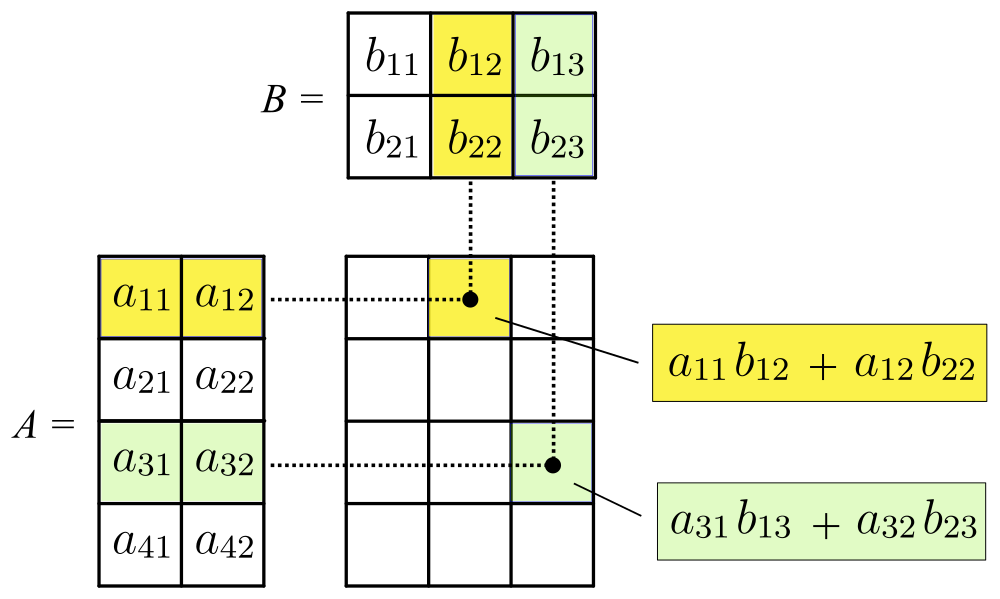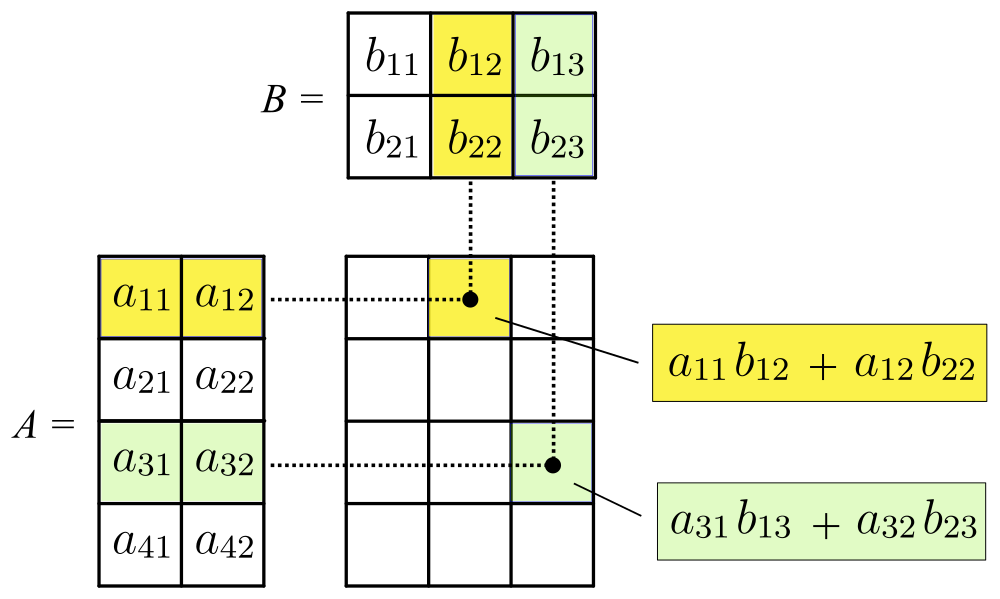

(https://en.wikipedia.org/wiki/Matrix_multiplication)

(https://en.wikipedia.org/wiki/Matrix_(mathematics))

## Matrix and column vector multiplication

First let's understand the multiplication of a 2x2 matrix and a 2x1 matrix of a single column vector:

Let's first create a 2x2 matrix:

In [ ]:
matA1 <- cbind(c(2,1), c(0.5,1.5))
matA1

And a 2x1 matrix:

In [ ]:
matB1 <- c(1,2) |> t() |> t()

In [ ]:
matB1

The multiplication:

${\displaystyle \mathbf{A}\mathbf{B}=\mathbf{C}}$

In [ ]:
matC1 <- matA1 %*% matB1
matC1

### Matrix multiplication as linear combination

We can interpret matrix multiplication first as the linear combination of the columns of $\mathbf A$:

In [ ]:
matB1

In [ ]:
matA1

First let's view the column vectors of $\mathbf A$ matrix:

In [ ]:
plot(NULL, xlim = c(-4, 4), ylim = c(-4, 4), asp = 1)
abline(h = 0, v = 0, col = "black", lty = 2, lwd = 2)
grid()
vectors(t(matA1), col = c("red", "blue"))

And let's scale each column vector with the scalars in $\mathbf B$:

In [ ]:
matA1r <- t(t(matA1) * matB1[T])

In [ ]:
matA1r

In [ ]:
plot(NULL, xlim = c(-4, 4), ylim = c(-4, 4), asp = 1)
abline(h = 0, v = 0, col = "black", lty = 2, lwd = 2)
grid()
vectors(t(matA1r), col = c("red", "blue"))

And sum the columns of scaled matrix $\mathbf A$:

In [ ]:
plot(NULL, xlim = c(-4, 4), ylim = c(-4, 4), asp = 1)
abline(h = 0, v = 0, col = "black", lty = 2, lwd = 2)
grid()
vectors(t(matA1r), col = c("red", "blue"))
vectors(t(matC1), col = c("black"))
vectors(t(matC1), origin = matA1r[,1], col = c("blue"))
vectors(t(matC1), origin = matA1r[,2], col = c("red"))

Let's plot all steps together:

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 7)
par(mfrow = c(1, 3))
plot(NULL, xlim = c(-4, 4), ylim = c(-4, 4), asp = 1)
abline(h = 0, v = 0, col = "black", lty = 2, lwd = 2)
grid()
vectors(t(matA1), col = c("red", "blue"))

plot(NULL, xlim = c(-4, 4), ylim = c(-4, 4), asp = 1)
abline(h = 0, v = 0, col = "black", lty = 2, lwd = 2)
grid()
vectors(t(matA1r), col = c("red", "blue"))

plot(NULL, xlim = c(-4, 4), ylim = c(-4, 4), asp = 1)
abline(h = 0, v = 0, col = "black", lty = 2, lwd = 2)
grid()
vectors(t(matA1r), col = c("red", "blue"))
vectors(t(matC1), col = c("black"))
vectors(t(matC1), origin = matA1r[,1], col = c("blue"))
vectors(t(matC1), origin = matA1r[,2], col = c("red"))

par(mfrow = c(1, 1))
options(repr.plot.width = 7, repr.plot.height = 7)

Now let's view $\mathbf A$, $\mathbf B$ and $\mathbf C$ together:

In [ ]:
plot(NULL, xlim = c(-4, 4), ylim = c(-4, 4), asp = 1)
abline(h = 0, v = 0, col = "black", lty = 2, lwd = 2)
grid()
vectors(t(matB1), col = "red")
vectors(t(matA1), col = "black")
vectors(t(matC1), col = "blue")

### Basis

In mathematics, a set B of elements of a vector space V is called a basis (pl.: bases) if every element of V can be written in a unique way as a finite linear combination of elements of B. The coefficients of this linear combination are referred to as components or coordinates of the vector with respect to B. The elements of a basis are called basis vectors.

Equivalently, a set B is a basis if its elements are linearly independent and every element of V is a linear combination of elements of B. In other words, a basis is a linearly independent spanning set.

(https://en.wikipedia.org/wiki/Basis_(linear_algebra))



#### Orthonormal basis

In mathematics, particularly linear algebra, an orthonormal basis for an inner product space V with finite dimension is a basis for V whose vectors are orthonormal, that is, they are all unit vectors and orthogonal to each other.

For example, the standard basis for a Euclidean space ℝn is an orthonormal basis, where the relevant inner product is the dot product of vectors. 

(https://en.wikipedia.org/wiki/Orthonormal_basis)

In mathematics, the standard basis (also called natural basis or canonical basis) of a coordinate vector space (such as 
ℝn is the set of vectors, each of whose components are all zero, except one that equals 1.

So each vector can be represented as a linear combination of standard basis vectors:

In [ ]:
matB1

In [ ]:
t(t(diag(2)) * matB1[T])

In [ ]:
as.matrix(rowSums(t(t(diag(2)) * matB1[T])))

#### Identity matrix

In linear algebra, the identity matrix of size n is the n×n square matrix with ones on the main diagonal and zeros elsewhere:

In [ ]:
diag(2)

### Matrix multiplication as transformation

A matrix multiplication $\mathbf A\mathbf B = \mathbf C$ can also be viewed as a transformation:

Each column vector of $\mathbf B$ is linear combination of standard basis vectors.

And each column vector of $\mathbf A$ takes the respective standard basis vector and transforms it by rotating, scaling or both (shearing).

So $\mathbf C$ is the linear combination of the transformed standard basis vectors.

Let's first view $\mathbf B$ as the linear combination of standard basis vectors:

In [ ]:
ax1 <- t(outer(matA1[,1], c(-20, 20)))
ar1 <- outer(ax1, seq(-20, 20, 1) * matA1[2,2], "+")

In [ ]:
ax2 <- t(outer(matA1[,2], c(-20, 20)))
ar2 <- outer(ax2, seq(-20, 20, 1) * matA1[1,1], "+")

In [ ]:
plot(NA, xlim = c(-3, 3), ylim = c(-3, 3))
abline(h = 0, v = 0, col = "black", lty = 2, lwd = 2)
grid()
vectors(diag(2), col = c("blue", "black"))
vectors(t(matB1), col = "pink")

Now let's view how each column of $\mathbf A$ transforms each respective standard basis vector:

In [ ]:
plot(NA, xlim = c(-3, 3), ylim = c(-3, 3))
abline(h = 0, v = 0, col = "black", lty = 2, lwd = 2)
grid()
vectors(diag(2), col = c("red", "blue"))
vectors(t(matA1), col = c("red", "blue"))
vectors(t(matA1)[1,], origin = c(1, 0), col = adjustcolor("pink", alpha.f = 0.3))
vectors(t(matA1)[2,], origin = c(0, 1), col = adjustcolor("lightblue", alpha.f = 0.3))

Now let's view $\mathbf C$ as the linear combination of transformed basis vectors. Note that in order to help understand the transformation, the standard grid is also sheared along with the transformed basis vectors:

In [ ]:
plot(NA, xlim = c(-4, 4), ylim = c(-4, 4))
lines(ax1, col = "black", lty = 2, lwd = 2)
lines(ax2, col = "black", lty = 2, lwd = 2)
a <- apply(ar1, 3, lines, col = "lightgray")
a <- apply(ar2, 3, lines, col = "lightgray")
vectors(t(matB1), col = "pink")
vectors(t(matA1), col = c("blue", "black"))
vectors(t(matC1), col = "red")

## Matrix and matrix multiplication

Now let's see the multiplication of two 2x2 matrices:

In [ ]:
matB2 <- cbind(c(1,2), c(2,1.5))

In [ ]:
matB2

In [ ]:
matA2 <- cbind(c(2,1), c(0.5,1.5))
matA2

In [ ]:
matC2 <- matA2 %*% matB2
matC2

### Matrix multiplication as linear combination

In [ ]:
plot(NULL, xlim = c(-4, 4), ylim = c(-4, 4), asp = 1)
abline(h = 0, v = 0, col = "black", lty = 2, lwd = 2)
grid()
vectors(t(matB2), col = c("pink", "red"))
vectors(t(matA2), col = "black")
vectors(t(matC2), col = c("lightblue", "blue"))

### Matrix multiplication as transformation

In [ ]:
ax1 <- t(outer(matA2[,1], c(-20, 20)))
ar1 <- outer(ax1, seq(-20, 20, 1) * matA2[2,2], "+")

In [ ]:
ax2 <- t(outer(matA2[,2], c(-20, 20)))
ar2 <- outer(ax2, seq(-20, 20, 1) * matA2[1,1], "+")

In [ ]:
plot(NA, xlim = c(-3, 3), ylim = c(-3, 3))
abline(h = 0, v = 0, col = "black", lty = 2, lwd = 2)
grid()
vectors(diag(2), col = c("red", "blue"))
vectors(t(matA2), col = c("red", "blue"))
vectors(t(matA2)[1,], origin = c(1, 0), col = adjustcolor("pink", alpha.f = 0.3))
vectors(t(matA2)[2,], origin = c(0, 1), col = adjustcolor("lightblue", alpha.f = 0.3))

In [ ]:
plot(NA, xlim = c(-4, 4), ylim = c(-4, 4))
lines(ax1, col = "black", lty = 2, lwd = 2)
lines(ax2, col = "black", lty = 2, lwd = 2)
a <- apply(ar1, 3, lines, col = "lightgray")
a <- apply(ar2, 3, lines, col = "lightgray")
vectors(t(matB2), col = "red")
vectors(t(matA2), col = "black")
vectors(t(matC2), col = "blue")

# Determinant

The determinant is a scalar-valued function of the entries of a square matrix that has many properties which make it fundamental for the study of square matrices and linear transformations represented by them.

The determinant of a matrix A is commonly denoted det(A), det A, or |A|. For square matrices of dimensions two and three, the determinant is explicitly described as

$\begin{aligned}\det \begin{bmatrix} a & b\\c & d \end{bmatrix}&= ad-bc,\\[10pt]\det \begin{bmatrix} a & b & c \\ d & e & f \\ g & h & i \end{bmatrix} &= aei + bfg + cdh - ceg - bdi - afh.\end{aligned}$

The value of the determinant is the scale factor by which the transformation alters every volume in the space the two column vectors $\begin{pmatrix} a \\ c \end{pmatrix}$ and
$\begin{pmatrix} b \\ d \end{pmatrix}$
of the matrix 
$\begin{pmatrix} a & b \\ c & d\end{pmatrix}$
define a parallelogram with vertices ⁠(0,0)⁠, ⁠(a,c), ⁠(b,d)⁠, and ⁠(a+b,c+d).
⁠The area of this parallogram is the absolute value of the determinant ⁠
ad − bc of the matrix.
The sign of the determinant determines the relative orientation of the vectors: the determinant is positive if one passes by a counterclockwise rotation from the direction of the vector ⁠(a,c) to that of⁠ (b,d)⁠, and negative if a clockwise rotation is needed (if the vectors are aligned, the determinant is zero). So, the determinant is the signed area of the parallelogram.

The n-dimensional volume of the parallelepiped generated by n vectors is the absolute value of the determinant of these vectors on standard basis.

(https://en.wikipedia.org/wiki/Determinant)

In [ ]:
paral <- function(u, v)
{
    x <- c(0, u[1], u[1] + v[1], v[1])
    y <- c(0, u[2], u[2] + v[2], v[2])
    list(x = x, y = y)
}

In [ ]:
plot(NA, xlim = c(-3, 4), ylim = c(-3, 4))
abline(h = 0, v = 0, col = "black", lty = 2, lwd = 2)
grid()
parc <- paral(matB2[, 1], matB2[, 2])
vectors(t(matB2), col = "red")
polygon(parc$x, parc$y, col="lightgrey", border=NA)

`diag` function can get the a and d terms from a 2x2 matrix. To get the b and c terms, let's create a function for antidiagonal entries:

In [ ]:
antidiag <- function(matx) matx[row(matx) + col(matx) == ncol(matx) + 1]

In [ ]:
matB2

In [ ]:
diag(matB2)

In [ ]:
antidiag(matB2)

Calculation of the determinant:

In [ ]:
prod(diag(matB2)) - prod(antidiag(matB2))

Or more easily:

In [ ]:
det(matB2)

In $\mathbf A\mathbf B = \mathbf C$ of square matrices, determinant of the product is the product of determinants:

In [ ]:
det(matA2)

In [ ]:
det(matC2)

In [ ]:
det(matA2) * det(matB2)

$\det(A)\det(B)=\det(C)$

$|A||B|=|C|$

Note that determinant is only defined for square matrices.

# Matrix inverse

An n-by-n square matrix A is called invertible if there exists an n-by-n square matrix B such that:

$\mathbf A\mathbf B = \mathbf B\mathbf A = \mathbf {I}_n$

If this is the case, then the matrix B is uniquely determined by A, and is called the inverse of A, denoted by $\mathbf A^{-1}$

(https://en.wikipedia.org/wiki/Invertible_matrix)

Suppose in the following operation:

$\mathbf A\mathbf B = \mathbf C$

We want to find B. In order to isolate B.

$\mathbf A^{-1}\mathbf A\mathbf B = \mathbf A^{-1}\mathbf C$

$\mathbf I_n\mathbf B = \mathbf A^{-1}\mathbf C$

$\mathbf B = \mathbf A^{-1}\mathbf C$

In [ ]:
solve(matA2) %*% matC2

In [ ]:
matB2

In [ ]:
plot(NULL, xlim = c(-4, 4), ylim = c(-4, 4), asp = 1)
abline(h = 0, v = 0, col = "black", lty = 2, lwd = 2)
grid()
vectors(t(matA2), col = "black")
vectors(t(solve(matA2)), col = "orange")

In [ ]:
matA2inv <- solve(matA2)

In [ ]:
matA2inv

In [ ]:
round(matA2inv %*% matA2, 10)

Determinant of inverse of A is 1 / det(A):

In [ ]:
1 / det(matA2)

In [ ]:
det(matA2inv)

## Solution to a system of linear equations

One of the basic applications of matrix inversion is to solve a system of linear equations.

Suppose we have:

$\begin{cases}3x+2y-z=1\\2x-2y+4z=-2\\-x+\frac{1}{2}y-z=0\end{cases}$

We can represent the system in matrix notation:

${\displaystyle \mathbf {A} ={\begin{bmatrix}3&2&-1\\2&-2&4\\-1&\frac{1}{2}&-1\end{bmatrix}},
\qquad {\mathbf {B }}={\begin{bmatrix}x\\y\\z\end{bmatrix}},
\qquad \mathbf {C} ={\begin{bmatrix}1\\-2\\0\end{bmatrix}}}$

So the solution to:

$\mathbf A\mathbf B = \mathbf C$

is:

$\mathbf B = \mathbf A^{-1}\mathbf C$

In [ ]:
A <- rbind(c(3,2,-1), c(2,-2,4), c(-1,1/2, -1))

In [ ]:
C <- cbind(c(1, -2, 0))
C

In [ ]:
B <- solve(A) %*% C

In [ ]:
A

In [ ]:
B

In [ ]:
C

In [ ]:
A %*% B

The solution vector is the coefficients of the linear combination of the column vectors of A which yields C.

From the row perspective, each row defines a 2D plane in 3D space. The solution is the intersection of three planes:

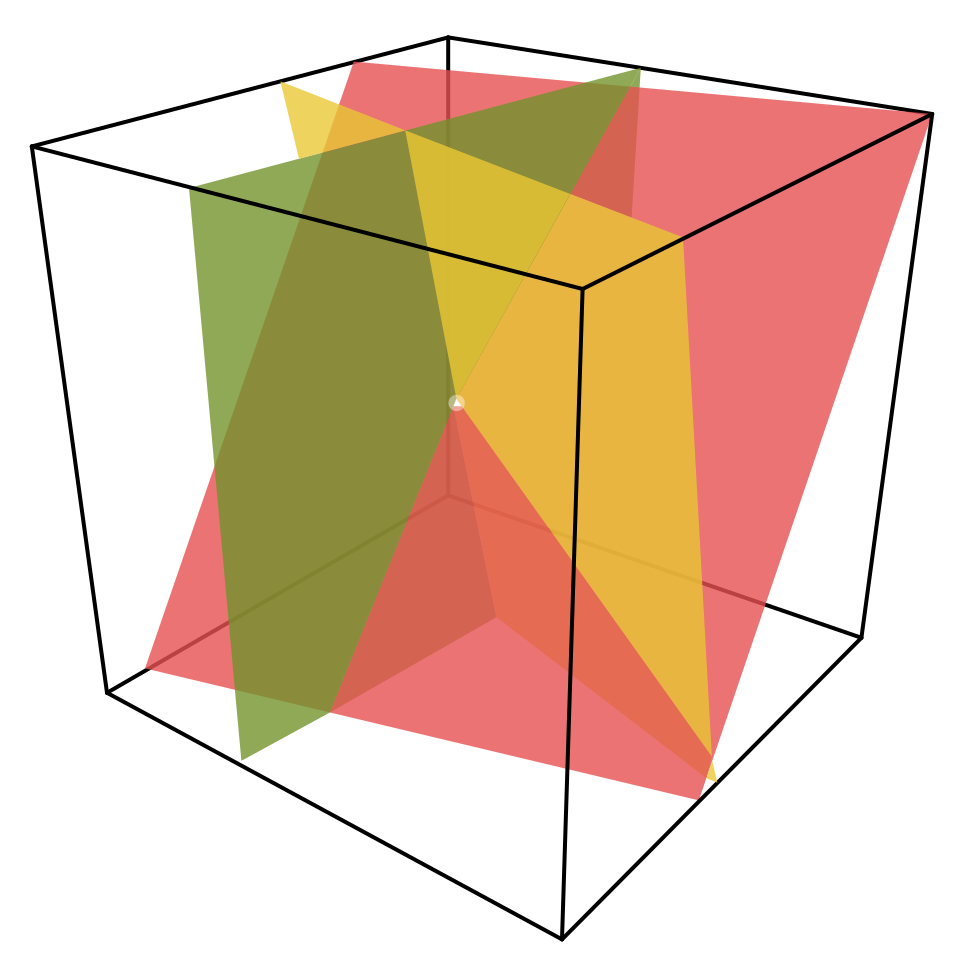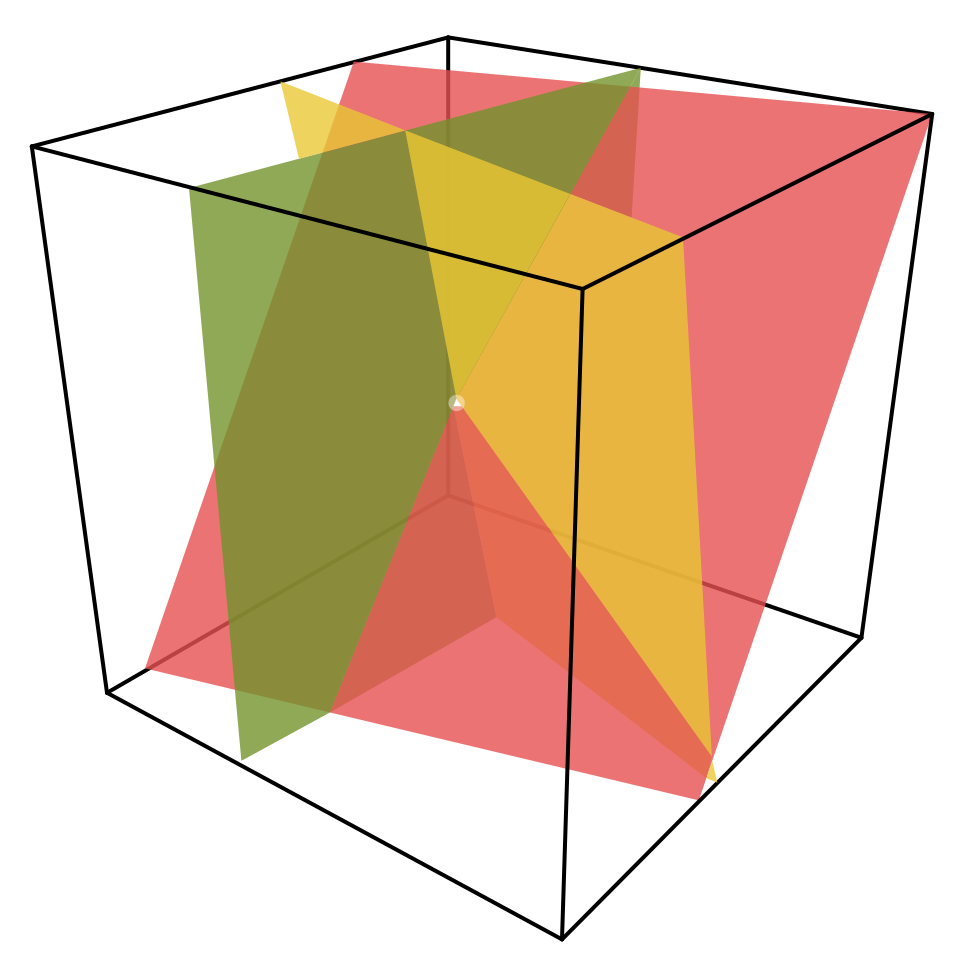

(https://en.wikipedia.org/wiki/System_of_linear_equations)

# Projection

The vector projection, also known as the vector component or vector resolution, of a vector a on (or onto) a non-zero vector b is the orthogonal projection of a onto a straight line parallel to b. The projection of a onto b is often written as

$\operatorname{proj}_\mathbf{b} \mathbf{a}$

The formula is:

$\text{proj}_{\mathbf{b}} \mathbf{a} = \frac{\mathbf{a} \cdot \mathbf{b}}{\|\mathbf{b}\|^2} \mathbf{b}$

The vector projection of a on b is a vector whose magnitude is the scalar projection of a on b with the same direction as b.

(https://en.wikipedia.org/wiki/Vector_projection)

Let's create a function for this:

In [ ]:
projvec <- function(u, v) sum(u * v) / sum(v * v) * v

In [ ]:
vec1

In [ ]:
vec2

In [ ]:
vec12 <- projvec(vec1, vec2)

In [ ]:
vec12

Let's plot these:

In [ ]:
plot(NULL, xlim = c(-1, 3), ylim = c(-1, 3), asp = 1)
abline(h = 0, v = 0, col = "black", lty = 2, lwd = 2)
grid()
vectors(t(vec1), col = adjustcolor("red", alpha.f = 0.3))
vectors(t(vec2), col = "black")
vectors(t(vec12), col = adjustcolor("blue", alpha.f = 0.3))
vectors(t(vec12), origin = t(vec1), col = "blue")

Since the projection is orthogonal, the residual vector or the difference between the original vector a and its projection onto b is orthogonal to vector b:

In [ ]:
res12 <- vec12 - vec1
res12

In [ ]:
round(sum(res12 * vec2), 10)

In [ ]:
rad2deg(vector_angle(res12, vec2))

# Eigenvector and eigenvalue

An eigenvector or characteristic vector is a (nonzero) vector that has its direction unchanged (or reversed) by a given linear transformation.

More precisely, an eigenvector 𝐯 of a linear transformation T is scaled by a constant factor λ when the linear transformation is applied to it: ⁠

$T\mathbf v = \lambda\mathbf v$

The corresponding eigenvalue, characteristic value, or characteristic root is the multiplying factor λ (possibly a negative or complex number).

Let's calculate the eigenvectors and eigenvalues of a matrix:

In [ ]:
matA2e <- eigen(matA2)

In [ ]:
matA2e

In [ ]:
matB3 <- matA2e$vectors

In [ ]:
matC3 <- matA2 %*% matB3

In [ ]:
matC3

See that the transformation does not rotate the vectors but just scales:

In [ ]:
plot(NULL, xlim = c(-1, 3), ylim = c(-1, 3), asp = 1)
abline(h = 0, v = 0, col = "black", lty = 2, lwd = 2)
grid()
vectors(t(matB3), col = adjustcolor("red", alpha.f = 0.3))
vectors(t(matA2), col = "black")
vectors(t(matC3), col = adjustcolor("blue", alpha.f = 0.3))

And showing the grid of transformation:

In [ ]:
plot(NA, xlim = c(-2, 4), ylim = c(-2, 4))
lines(ax1, col = "black", lty = 2, lwd = 2)
lines(ax2, col = "black", lty = 2, lwd = 2)
a <- apply(ar1, 3, lines, col = "lightgray")
a <- apply(ar2, 3, lines, col = "lightgray")
vectors(t(matB3), col = adjustcolor("red", alpha.f = 0.3))
vectors(t(matA2), col = "black")
vectors(t(matC3), col = adjustcolor("blue", alpha.f = 0.3))

And now let's check how the transformation scales the vectors of matrix B with the eigenvalues:

In [ ]:
eigv <- matA2e$values

In [ ]:
eigv

In [ ]:
matC3 / matB3

# Span and Rank

A vector space (also called a linear space) is a set whose elements, often called vectors, can be added together and multiplied ("scaled") by numbers called scalars. 

Vector spaces are characterized by their dimension, which, roughly speaking, specifies the number of independent directions in the space.

(https://en.wikipedia.org/wiki/Vector_space)

The linear span of a set S of elements of a vector space V is the smallest linear subspace of V that contains S.

It is the set of all finite linear combinations of the elements of S.

For example, two linearly independent vectors span a plane.

(https://en.wikipedia.org/wiki/Linear_span)

In linear algebra, the rank of a matrix A is the dimension of the vector space generated (or spanned) by its columns. This corresponds to the maximal number of linearly independent columns of A. This, in turn, is identical to the dimension of the vector space spanned by its rows.

(https://en.wikipedia.org/wiki/Rank_(linear_algebra))

Now let's create a 3 column matrix in 4 dimensions, such that the third column is the sum - hence a linear combination - of the first two:

In [ ]:
matD <- cbind(c(1,3,2,4), c(4,7,5,2))

In [ ]:
matD <- cbind(matD, rowSums(matD))

In [ ]:
matD

The rank of the column space of the matrix is 2:

In [ ]:
qr(matD)$rank

That means, the matrix has only 2 independent columns and the linear combinations of the columns of the matrix span only a 2D plane.

The rank of the row space of the matrix is the same:

In [ ]:
qr(t(matD))$rank

A square matrix, rank of which is equal to its dimension is full rank:

In [ ]:
dim(matA1)

In [ ]:
qr(matA1)$rank

The determinant of a full rank matrix is different than zero:

In [ ]:
det(matA1)

A rank deficient (non full rank) square matrix has a determinant equal to zero:

In [ ]:
matE <- cbind(c(1,3,2), c(4,7,5))

In [ ]:
matE <- cbind(matE, rowSums(matE))

In [ ]:
matE

In [ ]:
det(matE)

matE can be thought of as three vectors that lie on the same plane in 3D space.

Since they lie on the same plane, the parallelepiped defined by the vectors has NO volume and hence the determinant is zero.

## Null space

Null space or kernel of a matrix A is the solution to the equation:

$\mathbf A \mathbf x = 0$

where 0 is the zero vector all entries of which are zero.

(https://en.wikipedia.org/wiki/Kernel_(linear_algebra))

Let's calculate the null space of matrix D:

In [ ]:
null_space1 <- Null(t(matD))
null_space1

And confirm that it is the solution that maps D to zero vector:

In [ ]:
round(matD %*% null_space1, 10)

# Transpose, Gram matrix and symmetry

In linear algebra, transposition is an operation that flips a matrix over its diagonal; that is, transposition switches the row and column indices of the matrix A to produce another matrix, called the transpose of A and often denoted:

$A^T$

(https://en.wikipedia.org/wiki/Transpose)

In [ ]:
matD

In [ ]:
t(matD)

The Gram matrix (or Gramian matrix, Gramian) of vectors is the matrix of inner products, whose entries are given by the inner product:

$G_{ij} = \left\langle v_i, v_j \right\rangle$

and calculated as:

$X^\top X$

In [ ]:
matDg <- t(matD) %*% matD
matDg

A Gram matrix is square and symmetric.

The diagonal entries of a Gram matrix show the squared norms of the columns while off-diagonal entries show the pairwise alignment of vectors.

A symmetric matrix is equal to its transpose:

In [ ]:
identical(matDg, t(matDg))

Eigenvectors of a symmetric matrix are orthogonal to each other:

In [ ]:
matDei <- eigen(matDg)$vectors

In [ ]:
round(t(matDei) %*% matDei, 10)

The eigenvectors of the Gram matrix of a dataset is used in dimension reduction in data science.